*CS 545 final project · Ian Fisk, Ryan Baldwin · draft of the "Time series basics" section of `finalreport.ipynb`*

# Time series basics

Everything in this course so far has been about sequences of *words*. A sentence goes into BERT as a list of token ids, each id looks up a learned embedding, and attention mixes those embeddings into context-aware representations.

PatchTST applies the same transformer to a different kind of sequence: measurements taken over time. Before we can say what changes and why, we need to be precise about what that data looks like. This section answers three questions:

1. What is a time series, and what shape does it have as an array?
2. What structure (trend, seasons, noise) makes it predictable at all?
3. How do we turn one long series into training examples, and what exactly does a forecaster predict?

This draft covers questions 1 and 2.

In [1]:
# render figures as crisp vector graphics (SVG) in the notebook
try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
except ImportError:
    pass

import sys
import warnings
sys.path.append("..")          # src/, where the shared data loader lives

# NumPy 2.5 warns inside pandas' date arithmetic; it is not about our code.
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import ConnectionPatch, Rectangle
from IPython.display import HTML

from ltsf_data import load

# render animations as inline HTML players
plt.rcParams['animation.html'] = 'jshtml'
plt.rcParams['animation.embed_limit'] = 40  # MB

# colors and style shared by every figure in this section
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df"
SURFACE = "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]   # one color per channel or model
HILITE = "#eda100"                           # highlighted time steps
plt.rcParams.update({
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
})

def tidy(ax, grid=True):
    """Recessive axes: no top/right spines, light horizontal grid."""
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    if grid:
        ax.grid(axis="y", color=GRID, lw=1)
    ax.set_axisbelow(True)

## What is a time series?

A **time series** is a sequence of measurements taken at evenly spaced moments: one reading per hour, per 10 minutes, per day. When several quantities are measured on the same clock, we have a **multivariate** time series. Each quantity is called a **channel** (the papers also say *variate*).

Our running example is the CSU weather station in Fort Collins, which records 10 channels (temperature, humidity, wind, pressure, solar radiation, ...) once an hour. Loaded with our data loader, it is simply a 2-D array: one row per hour, one column per channel.

In [2]:
ts = load("csu_weather")
df = ts.df
print(ts)
print("values array shape:", ts.values.shape, " (n_steps, M)")
df.head()

TimeSeries('csu_weather', 52608 steps x M=10 channels, every h, 2020-01-01 00:00:00 -> 2025-12-31 23:00:00)
values array shape: (52608, 10)  (n_steps, M)


,Temp,RH,DewPt,Wind,WindDir,Gust,GustDir,Press,Solar,Prec
date,,,,,,,,,,
2020-01-01 00:00:00,28.900000,62.500000,17.700001,1.6,85.0,7.1,294.0,24.731001,0.0,0.0
2020-01-01 01:00:00,28.200001,61.599998,16.700001,2.2,319.0,10.1,246.0,24.705000,0.0,0.0
2020-01-01 02:00:00,28.200001,58.000000,15.300000,2.2,331.0,7.0,268.0,24.673000,0.0,0.0
2020-01-01 03:00:00,26.200001,63.099998,15.400000,2.2,236.0,6.6,246.0,24.652000,0.0,0.0
2020-01-01 04:00:00,24.700001,67.000000,15.300000,1.4,355.0,5.9,289.0,24.625000,0.0,0.0


Two ways of looking at that array, side by side. On the left, three of the channels plotted against time for one week in June 2023. On the right, the same numbers as rows of the table.

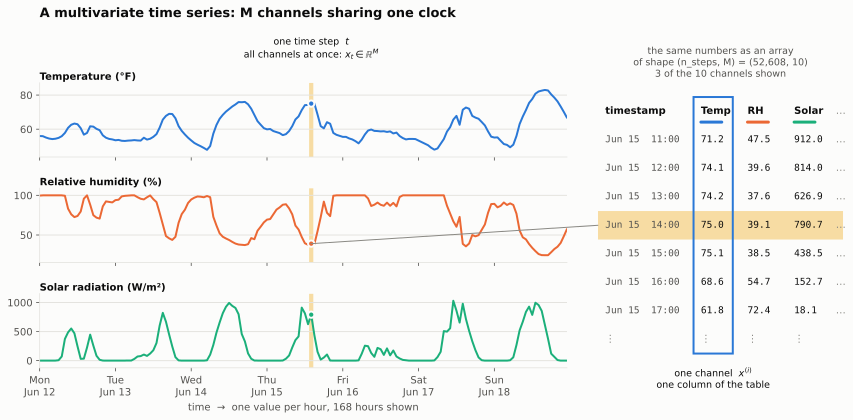

In [3]:
start = pd.Timestamp("2023-06-12 00:00")
week = df.loc[start: start + pd.Timedelta(hours=167)]
t_star = pd.Timestamp("2023-06-15 14:00")          # the one time step we highlight

channels = [("Temp", "Temperature", "°F"), ("RH", "Relative humidity", "%"),
            ("Solar", "Solar radiation", "W/m²")]

fig = plt.figure(figsize=(12, 6.0))
gs = fig.add_gridspec(3, 2, width_ratios=[2.15, 1], wspace=0.08, hspace=0.42,
                      left=0.06, right=0.99, top=0.80, bottom=0.14)
axes = [fig.add_subplot(gs[i, 0]) for i in range(3)]

for ax, (col, label, unit), color in zip(axes, channels, SERIES):
    ax.plot(week.index, week[col], color=color, lw=2, solid_capstyle="round")
    ax.axvspan(t_star - pd.Timedelta(minutes=40), t_star + pd.Timedelta(minutes=40),
               color=HILITE, alpha=0.35, lw=0)
    ax.scatter([t_star], [week.loc[t_star, col]], s=40, color=color,
               edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.set_title(f"{label} ({unit})", loc="left", color=INK, fontsize=10,
                 fontweight="bold", pad=3)
    ax.grid(axis="y", color=GRID, lw=1)
    ax.set_xlim(week.index[0], week.index[-1])
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.margins(y=0.12)
    if ax is not axes[-1]:
        ax.tick_params(labelbottom=False)

axes[-1].xaxis.set_major_locator(matplotlib.dates.DayLocator())
axes[-1].xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%a\n%b %d"))
axes[-1].set_xlabel("time  →  one value per hour, 168 hours shown", color=INK2)

# The time-step label above the top panel.
axes[0].annotate("one time step  $t$\nall channels at once: $x_t \\in \\mathbb{R}^M$",
                 xy=(matplotlib.dates.date2num(t_star), axes[0].get_ylim()[1]), xycoords="data",
                 xytext=(0, 22), textcoords="offset points",
                 ha="center", va="bottom", color=INK, fontsize=9.5,
                 annotation_clip=False)

# ---- the same numbers as a table ---------------------------------------------
tax = fig.add_subplot(gs[:, 1])
tax.set_axis_off(); tax.set_xlim(0, 1); tax.set_ylim(0, 1); tax.autoscale(False)
rows = df.loc[t_star - pd.Timedelta(hours=3): t_star + pd.Timedelta(hours=3)]
cols = ["Temp", "RH", "Solar"]
n_rows = len(rows) + 2                         # header + "…" row
row_h = 1.0 / (n_rows + 1)
col_x = [0.03, 0.42, 0.61, 0.80, 0.97]          # time, 3 channels, "…"

def cell_y(i):  # top of table = row 0
    return 1 - (i + 1) * row_h

tax.text(col_x[0], cell_y(0), "timestamp", fontweight="bold", color=INK, va="center")
for j, c in enumerate(cols):
    tax.text(col_x[j + 1], cell_y(0), c, ha="left", fontweight="bold", color=INK, va="center")
    tax.plot([col_x[j + 1], col_x[j + 1] + 0.085], [cell_y(0) - row_h * 0.38] * 2, color=SERIES[j],
             lw=3, solid_capstyle="round", transform=tax.transAxes)
tax.text(col_x[4], cell_y(0), "…", color=MUTED, va="center")

for i, (stamp, r) in enumerate(rows.iterrows(), start=1):
    y = cell_y(i)
    if stamp == t_star:
        tax.add_patch(Rectangle((0, y - row_h / 2), 1, row_h, color=HILITE, alpha=0.35,
                                lw=0, transform=tax.transAxes))
        hl_row_y = y
    tax.text(col_x[0], y, stamp.strftime("%b %d  %H:%M"), color=INK2, va="center",
             family="monospace", fontsize=9.5)
    for j, c in enumerate(cols):
        tax.text(col_x[j + 1], y, f"{r[c]:.1f}", color=INK, va="center",
                 family="monospace", fontsize=9.5)
    tax.text(col_x[4], y, "…", color=MUTED, va="center")
tax.text(col_x[0], cell_y(n_rows - 1), "⋮", color=MUTED, va="center")
for j in range(3):
    tax.text(col_x[j + 1], cell_y(n_rows - 1), "⋮", color=MUTED, va="center")

# Column highlight: one channel = one univariate series.
tax.add_patch(Rectangle((col_x[1] - 0.03, cell_y(n_rows - 1) - row_h / 2), 0.16,
                        (n_rows - 1) * row_h + row_h * 1.0, fill=False,
                        edgecolor=SERIES[0], lw=2, transform=tax.transAxes))
tax.text(col_x[1] + 0.05, cell_y(n_rows - 1) - row_h * 0.95,
         "one channel  $x^{(i)}$\none column of the table", ha="center", va="top",
         color=INK, fontsize=9.5)
tax.text(0.5, 1.01, "the same numbers as an array\nof shape (n_steps, M) = (52,608, 10)\n3 of the 10 channels shown",
         ha="center", va="bottom", transform=tax.transAxes, color=INK2, fontsize=9.5)

# Connector from the highlighted row back to the highlighted moment in the plot.
con = ConnectionPatch(xyA=(0, hl_row_y), coordsA=tax.transAxes,
                      xyB=(matplotlib.dates.date2num(t_star), float(week.loc[t_star, "RH"])), coordsB=axes[1].transData,
                      color=MUTED, lw=1, arrowstyle="-", linestyle="-")
fig.add_artist(con)

fig.suptitle("A multivariate time series: M channels sharing one clock",
             x=0.06, y=0.975, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.show()

### Reading the figure

- **A row is one moment.** The highlighted row is 2pm on June 15: the value of every channel at that hour. In the papers' notation it is a vector $x_t \in \mathbb{R}^M$, where $M$ is the number of channels.
- **A column is one channel over time.** The boxed column is the temperature series by itself, a *univariate* time series $x^{(i)}$. PatchTST's channel independence, which we meet later, treats each column as a separate input.
- **The channels share a clock but not a unit.** Temperature is in °F, humidity in %, solar radiation in W/m². Their scales differ by a factor of 10 or more, which is why each channel is normalized separately before it goes into a model.

The plot also shows the kind of structure forecasting depends on:

- Solar radiation rises and falls once every 24 hours: a **daily season**, 24 steps long at hourly sampling.
- Temperature follows the sun with a lag. In the table, solar radiation is highest by 11am but temperature keeps rising until 3pm.
- Humidity moves opposite to temperature: it drops in the warm afternoons and climbs back to 100% at night.

### How this differs from text

A sentence and a time series are both sequences, but they differ in ways that matter for a transformer:

| | Text (BERT, GPT) | Time series |
|---|---|---|
| One element | a token id from a fixed vocabulary | a vector of $M$ real numbers |
| Meaning of one element | a word means something on its own | 75.0°F says almost nothing without its neighbours |
| How elements enter the model | embedding lookup table | a learned linear projection of real values |
| Typical length | hundreds of tokens | thousands of time steps (52,608 here) |

The second row is the important one. A single time step carries very little information. The pattern only appears across many neighbouring steps, and that observation is what motivates PatchTST's *patches*.

## Columns in the file, rows in the plot

A small thing that causes a lot of confusion when you start working with this data. In the file, time runs *down* the rows, so a channel is a **column**. Every plot of a time series runs time *left to right*, so the same channel is drawn **horizontally**. Models follow the plots: they transpose the array so that each channel is a **row**.

In [4]:
hours = df.loc["2023-06-15 06:00":"2023-06-15 17:00"]
vals = hours["Temp"].to_numpy()
n = len(vals)                                       # 12 hourly readings
lo, hi = vals.min(), vals.max()
rise_to = lambda v: 1.0 + 3.8 * (v - lo) / (hi - lo)  # plot height for a value

F_TABLE, F_ROT, F_RISE, F_HOLD = 10, 22, 22, 16
ease = lambda u: 0.5 - 0.5 * np.cos(np.pi * np.clip(u, 0, 1))

fig = plt.figure(figsize=(9, 5.2), dpi=80)
ax = fig.add_axes([0, 0, 1, 1])
RATIO = 5.2 / 9                                     # keeps cells square while the view pans

def view(r):
    """Camera: zoomed out on the tall column, then onto the horizontal plot."""
    w = 30.0 + r * (14.2 - 30.0)
    cx, cy = 5.0 + r * (5.5 - 5.0), -4.6 + r * (2.6 - -4.6)
    ax.set_xlim(cx - w / 2, cx + w / 2)
    ax.set_ylim(cy - w * RATIO / 2, cy + w * RATIO / 2)

def caption(text):
    ax.text(0.03, 0.95, text, transform=ax.transAxes, ha="left", va="top",
            fontsize=12, color=INK, wrap=True)

def frame(f):
    ax.clear(); ax.set_axis_off()
    r = ease((f - F_TABLE) / F_ROT)                 # rotation progress 0 -> 1
    s = ease((f - F_TABLE - F_ROT) / F_RISE)        # rise progress 0 -> 1
    view(r)
    theta = r * np.pi / 2

    # the neighbouring columns of the table fade away as the column turns
    if r < 1:
        for j, c in enumerate(["RH", "Solar"]):
            x = 1.25 * (j + 1)
            ax.text(x, 0.9, c, ha="center", fontsize=9, color=INK2, alpha=1 - r)
            for i, v in enumerate(hours[c]):
                ax.text(x, -i, f"{v:.0f}", ha="center", va="center",
                        fontsize=8, color=MUTED, alpha=1 - r)
        ax.text(0, 0.9, "Temp", ha="center", fontsize=9, color=INK, fontweight="bold",
                alpha=1 - r)
        for i, stamp in enumerate(hours.index):
            ax.text(-0.75, -i, stamp.strftime("%H:%M"), ha="right", va="center",
                    fontsize=8, color=INK2, alpha=1 - r)

    xs, ys = [], []
    for i, v in enumerate(vals):
        x, y = i * np.sin(theta), -i * np.cos(theta)  # rotate the column 90 degrees
        y += s * rise_to(v)                           # then lift each value to its height
        xs.append(x); ys.append(y)
        size = 0.86 * (1 - s)
        if size > 0.04:
            ax.add_patch(Rectangle((x - size / 2, y - size / 2), size, size,
                                   facecolor=SURFACE, edgecolor=SERIES[0], lw=1.5))
        if s < 0.6:
            ax.text(x, y, f"{v:.1f}", ha="center", va="center", fontsize=7.5 + 0.5 * r,
                    color=INK, alpha=1 - s / 0.6)
    if s > 0:
        ax.plot(xs, ys, color=SERIES[0], lw=2, alpha=s, solid_capstyle="round")
        ax.scatter(xs, ys, s=30 * s, color=SERIES[0], edgecolor=SURFACE, lw=1.5, zorder=3)
        for i, stamp in enumerate(hours.index):
            if i % 2 == 0:
                ax.text(i, -0.55, stamp.strftime("%H:%M"), ha="center", va="top",
                        fontsize=8, color=INK2, alpha=s)
        ax.plot([-0.5, n - 0.5], [0, 0], color=GRID, lw=1, alpha=s)
        ax.text(n - 0.4, -0.55, "time →", ha="left", va="top", fontsize=9, color=INK2, alpha=s)
        for v in (lo, hi):
            ax.text(-0.7, rise_to(v), f"{v:.1f} °F", ha="right", va="center",
                    fontsize=8, color=INK2, alpha=s)

    if f < F_TABLE:
        caption("In the file, time runs DOWN the rows.\nThe temperature channel is one column.")
    elif f < F_TABLE + F_ROT:
        caption("Turn that column on its side ...")
    elif f < F_TABLE + F_ROT + F_RISE:
        caption("... and let each value set a height:\nthe usual time series plot, time running left to right.")
    else:
        caption("This is also how models store it: the input X has shape (M, L),\n"
                "so every channel is one ROW of L time steps.")

anim = FuncAnimation(fig, frame, frames=F_TABLE + F_ROT + F_RISE + F_HOLD, interval=1000 / 10)
plt.close(fig)
anim

In code the turn is a single transpose. Take the 12 hours from the animation, all 10 channels:

In [5]:
window = df.loc["2023-06-15 06:00":"2023-06-15 17:00"].to_numpy()   # as stored: (L, M)
X = window.T                                                       # as a model sees it: (M, L)
print("stored:", window.shape, "   model input:", X.shape)
print("temperature row of X:", X[ts.channels.index("Temp")])

stored: (12, 10)    model input: (10, 12)
temperature row of X: [57.1 58.9 61.8 65.7 67.5 71.2 74.1 74.2 75.  75.1 68.6 61.8]


This is the layout used throughout the project: the windows built by our training code have shape `(batch, M, L)`, so `X[b, i]` is the look-back window of channel $i$ in example $b$, a row of $L$ numbers.

## Trend, seasons and noise

Why can we forecast a time series at all? Because most real series are built from a few kinds of structure, each of which says something different about the future:

- a **trend**: slow, steady change, like a level that keeps rising;
- one or more **seasons**: patterns that repeat with a fixed period, like a daily or weekly cycle;
- **noise**: random variation that is different at every step and cannot be predicted.

With real data we never get to see these parts separately. So we start with a **synthetic** series, where we choose every part ourselves and add them up.

In [6]:
def make_synthetic(n_steps=24 * 28, trend=0.0, seasons=(), noise=0.0, seed=0):
    """
    An hourly synthetic series built from parts we control exactly.

    trend:   total rise over the whole series (a straight line)
    seasons: list of (period, amplitude): a sine wave repeating every `period` steps
    noise:   standard deviation of independent Gaussian noise at each step

    Returns a dict of the separate parts plus their sum under "series".
    """
    t = np.arange(n_steps)
    rng = np.random.default_rng(seed)
    parts = {"trend": trend * t / n_steps}
    for period, amplitude in seasons:
        parts[f"season ({period} steps)"] = amplitude * np.sin(2 * np.pi * t / period)
    parts["noise"] = noise * rng.standard_normal(n_steps)
    parts["series"] = sum(parts.values())
    return parts

synth = make_synthetic(trend=6, seasons=[(24, 3), (168, 1.5)], noise=0.8)

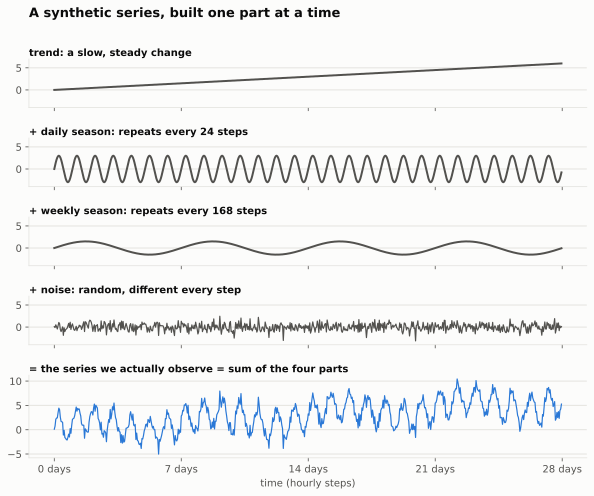

In [7]:
labels = {"trend": "trend: a slow, steady change",
          "season (24 steps)": "daily season: repeats every 24 steps",
          "season (168 steps)": "weekly season: repeats every 168 steps",
          "noise": "noise: random, different every step",
          "series": "the series we actually observe = sum of the four parts"}
names = list(labels)
t = np.arange(len(synth["series"]))

fig, axes = plt.subplots(len(names), 1, figsize=(10, 7.2), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 1, 1, 1.7], "hspace": 0.55})
for k, (ax, name) in enumerate(zip(axes, names)):
    observed = name == "series"
    ax.plot(t, synth[name], color=SERIES[0] if observed else INK2,
            lw=1.2 if name in ("noise", "series") else 2)
    ax.set_title(("" if k == 0 else ("= " if observed else "+ ")) + labels[name],
                 loc="left", fontsize=10, color=INK, fontweight="bold", pad=3)
    if not observed:
        ax.set_ylim(-4, 7)
    tidy(ax)
axes[-1].set_xticks(np.arange(0, len(t) + 1, 168))
axes[-1].set_xticklabels([f"{d} days" for d in range(0, 29, 7)])
axes[-1].set_xlabel("time (hourly steps)")
fig.suptitle("A synthetic series, built one part at a time", x=0.125, ha="left",
             fontsize=13, fontweight="bold", color=INK)
plt.show()

Two details carry over to real data:

- A series can have **several seasons at once**. Here a daily cycle rides on top of a weekly one.
- A season's length is counted in **steps**, so it depends on how often we sample. One day is 24 steps of hourly data, but 144 steps of the Weather benchmark, which records every 10 minutes.

### The same parts in real data

Here is the CSU temperature channel at three zoom levels.

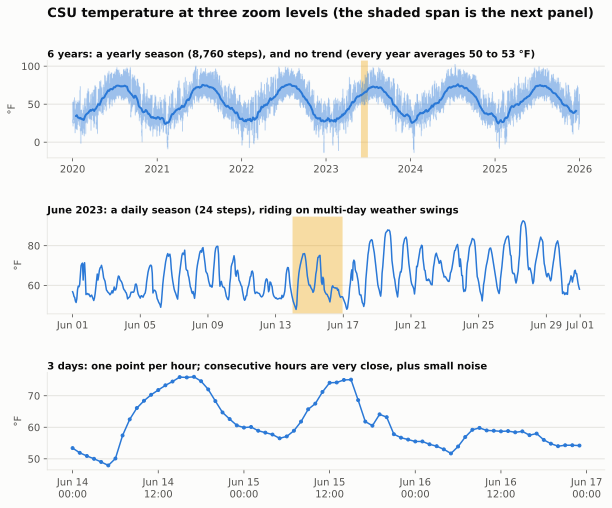

In [8]:
temp = df["Temp"]
month = slice("2023-06-01", "2023-06-30 23:00")
days = slice("2023-06-14", "2023-06-16 23:00")

fig, axes = plt.subplots(3, 1, figsize=(10, 7.4), gridspec_kw={"hspace": 0.6})

ax = axes[0]
ax.plot(temp.index, temp, color=SERIES[0], lw=0.4, alpha=0.45, rasterized=True)
ax.plot(temp.index, temp.rolling(24 * 30, center=True).mean(), color=SERIES[0], lw=2)
ax.axvspan(pd.Timestamp(month.start), pd.Timestamp(month.stop), color=HILITE, alpha=0.35, lw=0)
ax.set_title("6 years: a yearly season (8,760 steps), and no trend (every year averages 50 to 53 °F)",
             loc="left", fontsize=10, fontweight="bold", pad=3)

ax = axes[1]
m = temp.loc[month]
ax.plot(m.index, m, color=SERIES[0], lw=1.5)
ax.axvspan(pd.Timestamp(days.start), pd.Timestamp(days.stop), color=HILITE, alpha=0.35, lw=0)
ax.set_title("June 2023: a daily season (24 steps), riding on multi-day weather swings",
             loc="left", fontsize=10, fontweight="bold", pad=3)
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %d"))

ax = axes[2]
d = temp.loc[days]
ax.plot(d.index, d, color=SERIES[0], lw=1.5, marker="o", ms=3)
ax.set_title("3 days: one point per hour; consecutive hours are very close, plus small noise",
             loc="left", fontsize=10, fontweight="bold", pad=3)
ax.xaxis.set_major_locator(matplotlib.dates.HourLocator(byhour=[0, 12]))
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %d\n%H:%M"))

for ax in axes:
    ax.set_ylabel("°F")
    tidy(ax)
fig.suptitle("CSU temperature at three zoom levels (the shaded span is the next panel)",
             x=0.125, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.show()

- **6 years:** a strong **yearly season**, 8,760 steps long. There is no visible trend: every year averages between 50 and 53 °F.
- **One month:** the **daily season** appears, but it sits on top of irregular swings lasting several days, as warm and cold weather systems pass through. Those swings are neither a fixed season nor step-to-step noise, and they are the hardest part to forecast.
- **Three days:** neighbouring hours are very close to each other. The noise is small compared with the daily cycle.

The last point is why a single time step means so little: at hourly resolution, one reading is almost the same as the one before it. The information is in the *shape* traced out over many steps.

### Measuring seasons with autocorrelation

Eyeballing a plot only goes so far. The **autocorrelation** at lag $k$ is the correlation between the series and a copy of itself shifted $k$ steps back: between $x_t$ and $x_{t-k}$ over all $t$. If the series repeats every $p$ steps, the autocorrelation peaks at $k = p, 2p, 3p, \dots$

Below we compare temperature with the Traffic benchmark (road occupancy from 862 freeway sensors). For Traffic we average the autocorrelation over all sensors.

In [9]:
def autocorrelation(x, max_lag):
    """Correlation between the series and itself shifted by k steps, for k = 0..max_lag."""
    x = x - x.mean()
    f = np.fft.rfft(x, n=2 * len(x))                 # FFT trick: all lags at once
    acf = np.fft.irfft(f * np.conj(f))[:max_lag + 1]
    return acf / acf[0]

max_lag = 24 * 16
acf_temp = autocorrelation(ts.channel("Temp"), max_lag)

traffic = load("traffic")                            # 862 road sensors, hourly
acf_traffic = np.mean([autocorrelation(traffic.values[:, i], max_lag)
                       for i in range(traffic.values.shape[1])], axis=0)

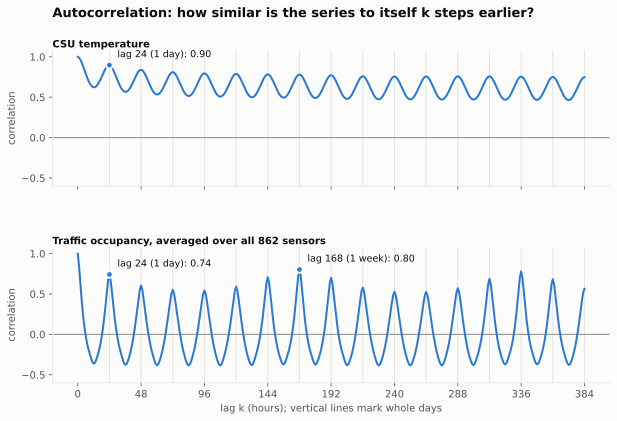

In [10]:
lags = np.arange(max_lag + 1)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"hspace": 0.45})
panels = [(axes[0], acf_temp, "CSU temperature", [24]),
          (axes[1], acf_traffic, "Traffic occupancy, averaged over all 862 sensors", [24, 168])]
for ax, acf, title, marks in panels:
    for k in range(24, max_lag + 1, 24):               # every whole day
        ax.axvline(k, color=GRID, lw=1, zorder=0)
    ax.axhline(0, color=MUTED, lw=1)
    ax.plot(lags, acf, color=SERIES[0], lw=2)
    for k in marks:
        ax.scatter([k], [acf[k]], s=45, color=SERIES[0], edgecolor=SURFACE, lw=2, zorder=3)
        name = {24: "1 day", 168: "1 week"}[k]
        ax.annotate(f"lag {k} ({name}): {acf[k]:.2f}", (k, acf[k]), xytext=(8, 8),
                    textcoords="offset points", fontsize=9.5, color=INK)
    ax.set_title(title, loc="left", fontsize=10, fontweight="bold", pad=3)
    ax.set_ylabel("correlation")
    ax.set_ylim(-0.6, 1.08)
    tidy(ax, grid=False)
axes[-1].set_xticks(np.arange(0, max_lag + 1, 48))
axes[-1].set_xlabel("lag k (hours); vertical lines mark whole days")
fig.suptitle("Autocorrelation: how similar is the series to itself k steps earlier?",
             x=0.125, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.show()

- **Temperature** peaks every 24 hours: one daily season. At lag 24 the correlation is 0.90, meaning the temperature at this hour tomorrow is very close to the temperature now.
- **Traffic** also peaks every 24 hours, but the highest peak is at **168 hours, one week**. Traffic on a Tuesday looks most like traffic on the previous Tuesday, because weekdays and weekends differ.

This is the measurement behind our seasonal baseline, which forecasts by repeating the last season. Ian's sweep over the repeat period found the best period for Traffic on week boundaries, just as the autocorrelation predicts. (Traffic's timestamps are placeholders, see `data/README.md`, but lags count steps, not calendar dates, so this analysis is unaffected.)

### Separating the parts: moving-average decomposition

To use these parts, a model first has to pull them apart. The classical tool is a **moving average**: replace each value by the average of the $k$ values around it. Anything that repeats within the window averages out, leaving a smooth **trend**. Subtracting the trend leaves the **season plus noise**.

This is exactly the preprocessing step of **DLinear**, one of the simple linear models from Zeng et al. (2023), §4, who took it from the earlier Autoformer. DLinear's released code uses a window of 25 steps, slightly more than one day of hourly data. We try it on a synthetic series, where we know the right answer, and then on real temperature.

In [11]:
def moving_average(x, kernel=25):
    """Average over a sliding window of `kernel` steps. The ends are padded by repeating
    the first and last value, so the output has the same length as the input (as in DLinear)."""
    pad = (kernel - 1) // 2
    padded = np.concatenate([np.repeat(x[:1], pad), x, np.repeat(x[-1:], kernel - 1 - pad)])
    return np.convolve(padded, np.ones(kernel) / kernel, mode="valid")

def decompose(x, kernel=25):
    """Split a series into a smooth trend and everything left over (season + noise)."""
    trend = moving_average(x, kernel)
    return trend, x - trend

# A synthetic series where we know the true parts, and a real one where we don't.
demo = make_synthetic(n_steps=24 * 14, trend=4, seasons=[(24, 3)], noise=0.6, seed=1)
syn_trend, syn_rest = decompose(demo["series"])

real = df["Temp"].loc["2023-06-05":"2023-06-18 23:00"]
real_trend, real_rest = decompose(real.to_numpy())

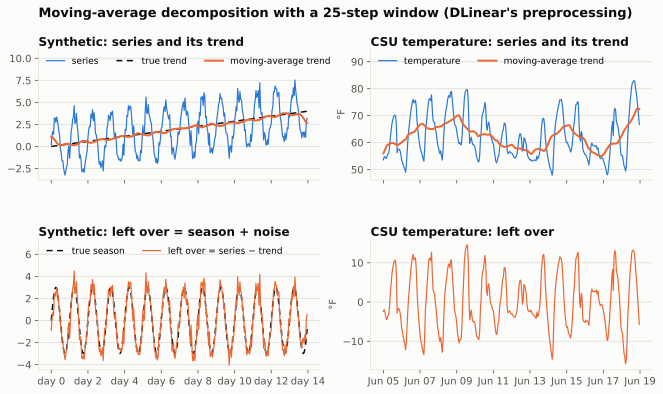

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.8), sharex="col",
                         gridspec_kw={"hspace": 0.45, "wspace": 0.18})
t = np.arange(len(demo["series"]))

ax = axes[0, 0]
ax.plot(t, demo["series"], color=SERIES[0], lw=1.2, label="series")
ax.plot(t, demo["trend"], color=INK, lw=1.5, ls=(0, (4, 3)), label="true trend")
ax.plot(t, syn_trend, color=SERIES[1], lw=2, label="moving-average trend")
ax.set_title("Synthetic: series and its trend", loc="left", fontweight="bold", pad=3)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=3)

ax = axes[1, 0]
ax.plot(t, demo["season (24 steps)"], color=INK, lw=1.5, ls=(0, (4, 3)), label="true season")
ax.plot(t, syn_rest, color=SERIES[1], lw=1.2, label="left over = series − trend")
ax.set_title("Synthetic: left over = season + noise", loc="left", fontweight="bold", pad=3)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
ax.set_xticks(np.arange(0, len(t) + 1, 48))
ax.set_xticklabels([f"day {d}" for d in range(0, 15, 2)])

ax = axes[0, 1]
ax.plot(real.index, real, color=SERIES[0], lw=1.2, label="temperature")
ax.plot(real.index, real_trend, color=SERIES[1], lw=2, label="moving-average trend")
ax.set_title("CSU temperature: series and its trend", loc="left", fontweight="bold", pad=3)
ax.legend(frameon=False, fontsize=9, loc="upper left", ncol=2)
ax.set_ylabel("°F")

ax = axes[1, 1]
ax.plot(real.index, real_rest, color=SERIES[1], lw=1.2)
ax.set_title("CSU temperature: left over", loc="left", fontweight="bold", pad=3)
ax.set_ylabel("°F")
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter("%b %d"))

for a in axes.flat:
    tidy(a)
axes[0, 0].set_ylim(top=axes[0, 0].get_ylim()[1] + 3)
axes[1, 0].set_ylim(top=axes[1, 0].get_ylim()[1] + 2.5)
axes[0, 1].set_ylim(top=axes[0, 1].get_ylim()[1] + 10)
fig.suptitle("Moving-average decomposition with a 25-step window (DLinear's preprocessing)",
             x=0.125, ha="left", fontsize=13, fontweight="bold", color=INK)
plt.show()

- **Synthetic (left):** the moving-average trend follows the true trend closely, and what is left over matches the true daily season plus noise.
- **Real temperature (right):** a 25-step window averages out the daily cycle, so whatever is slower than a day ends up in the "trend": here, the multi-day weather swings. In these papers, "trend" really means *the slow part of the window*, not a long-term rise.
- **The ends bend.** At the edges the window runs out of data, so the code repeats the first and last value. The estimate is least reliable at the very end of the window, the most recent steps, which is exactly where a forecast begins.

### Why this matters for forecasting

| Part | How a forecaster can use it | Where it appears in our project |
|---|---|---|
| Trend | continue it | DLinear's trend branch; instance normalization (RevIN) removes each window's level |
| Season | repeat it | the seasonal baseline; the learned weights of the linear models |
| Noise | it cannot | sets a floor on the error any model can reach |

The irregular weather swings fall between these categories. Predicting them requires a model that reads the recent history and recognises what is happening, which is where learned models have to beat simple baselines.

## Coming next

- **From one series to training examples:** sliding a look-back window of length $L$ and a horizon of length $T$ along the series, and the array shapes that produces, $(n\_steps, M) \rightarrow (N, M, L)$.
- **Predicting the whole horizon at once vs. step by step:** why LTSF models output all $T$ future values in one shot instead of generating them one at a time like an LLM.
- **Distribution shift:** the training and test periods have different levels and spreads, which is what instance normalization fixes.